Functional Connectivity of Imagined Speech and Visual Imagery based on Spectral Dynamics 재현 코드

데이터셋
- Lee et al. Towards an EEG-based  intuitive BCI communication system using imagined speech and visal imageryry

논문 전처리 과정 - EEGLAB
1. 256Hz로 down sampling, 0.5-125Hz로 band-pass filtering
2. 60Hz Notch filter
3. Re-referencing: Common Average Reference
4. 2000ms epoch 추출
5. -500ms 기준으로 baseline 보정
6. 4개 주파수 대역(델타, 세타, 알파, 베타)으로 필터링
7. 안구와 근육 아티팩트는 automatic algorithms with  second-order blind identification and blind source canonica 
 correlation analysis으로 제거
 

이 코드에서 사용한 데이터셋
- "thinking out loud, an open-access EEG-based BCI dataset for inner speech recognition"의 open-access 데이터

In [34]:
import mne
import pandas as pd
from mne.preprocessing import ICA
from mne_icalabel import label_components

In [2]:
base_path = "D:/Users/windows/Desktop/EEG Inner Speech Decoding/Dataset/"

In [3]:
# subject, session 설정
subject = 'sub-01'
session = 'ses-01'

In [4]:
file_path = f"{base_path}/{subject}/{session}/eeg/{subject}_{session}_task-innerspeech_eeg.bdf"

In [5]:
raw = mne.io.read_raw_bdf(file_path, preload=True, verbose="Warning")
raw

<RawEDF | sub-01_ses-01_task-innerspeech_eeg.bdf, 137 x 1875968 (1832.0 s), ~1.91 GiB, data loaded>

In [6]:
channels = raw.info['ch_names']
channels

['A1',
 'A2',
 'A3',
 'A4',
 'A5',
 'A6',
 'A7',
 'A8',
 'A9',
 'A10',
 'A11',
 'A12',
 'A13',
 'A14',
 'A15',
 'A16',
 'A17',
 'A18',
 'A19',
 'A20',
 'A21',
 'A22',
 'A23',
 'A24',
 'A25',
 'A26',
 'A27',
 'A28',
 'A29',
 'A30',
 'A31',
 'A32',
 'B1',
 'B2',
 'B3',
 'B4',
 'B5',
 'B6',
 'B7',
 'B8',
 'B9',
 'B10',
 'B11',
 'B12',
 'B13',
 'B14',
 'B15',
 'B16',
 'B17',
 'B18',
 'B19',
 'B20',
 'B21',
 'B22',
 'B23',
 'B24',
 'B25',
 'B26',
 'B27',
 'B28',
 'B29',
 'B30',
 'B31',
 'B32',
 'C1',
 'C2',
 'C3',
 'C4',
 'C5',
 'C6',
 'C7',
 'C8',
 'C9',
 'C10',
 'C11',
 'C12',
 'C13',
 'C14',
 'C15',
 'C16',
 'C17',
 'C18',
 'C19',
 'C20',
 'C21',
 'C22',
 'C23',
 'C24',
 'C25',
 'C26',
 'C27',
 'C28',
 'C29',
 'C30',
 'C31',
 'C32',
 'D1',
 'D2',
 'D3',
 'D4',
 'D5',
 'D6',
 'D7',
 'D8',
 'D9',
 'D10',
 'D11',
 'D12',
 'D13',
 'D14',
 'D15',
 'D16',
 'D17',
 'D18',
 'D19',
 'D20',
 'D21',
 'D22',
 'D23',
 'D24',
 'D25',
 'D26',
 'D27',
 'D28',
 'D29',
 'D30',
 'D31',
 'D32',
 'EXG1',
 'E

In [7]:
events = mne.find_events(raw, shortest_event=1, verbose=True)

Trigger channel Status has a non-zero initial value of 65536 (consider using initial_event=True to detect this event)
Removing orphaned offset at the beginning of the file.
1112 events found on stim channel Status
Event IDs: [11 12 13 14 15 16 17 21 22 23 31 32 33 34 42 44 45 46 51 61 62 63 64]


In [8]:
print(events)
print(len(events))

[[   6283       0      11]
 [  16591       0      13]
 [  31976       0      14]
 ...
 [1829105       0      46]
 [1829126       0      16]
 [1829156       0      12]]
1112


In [9]:
ref_channels=['EXG1', 'EXG2']

# Re-referencing
raw.set_eeg_reference(ref_channels=ref_channels)

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.


<RawEDF | sub-01_ses-01_task-innerspeech_eeg.bdf, 137 x 1875968 (1832.0 s), ~1.91 GiB, data loaded>

In [10]:
eeg_d = raw.get_data()
print(eeg_d)

[[-2.35148003e-03 -2.35246440e-03 -2.35110503e-03 ... -3.26463459e-03
  -3.26415022e-03 -3.26793146e-03]
 [-1.38929431e-03 -1.38843493e-03 -1.38729431e-03 ... -1.12838854e-03
  -1.12740417e-03 -1.13134166e-03]
 [-2.30501137e-03 -2.30671449e-03 -2.30504262e-03 ... -1.49366912e-03
  -1.49212224e-03 -1.49530974e-03]
 ...
 [-1.33398660e-02 -1.33194754e-02 -1.32998973e-02 ... -1.22598055e-02
  -1.22193212e-02 -1.22230712e-02]
 [-1.30762727e-02 -1.30856946e-02 -1.30888039e-02 ... -1.05180899e-02
  -1.04902619e-02 -1.04565119e-02]
 [ 6.55360000e+04  6.55360000e+04  6.55360000e+04 ...  0.00000000e+00
   0.00000000e+00  0.00000000e+00]]


In [11]:
print(eeg_d.shape)

(137, 1875968)


In [12]:
channel_names = raw.ch_names

# Convert the NumPy array to a DataFrame
df = pd.DataFrame(eeg_d.T, columns=channel_names)
df

,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,...,D32,EXG1,EXG2,EXG3,EXG4,EXG5,EXG6,EXG7,EXG8,Status
0,-0.002351,-0.001389,-0.002305,-0.002834,-0.007268,0.000217,-0.010027,-0.008167,-0.004082,-0.008715,...,-0.011488,0.002094,-0.002094,-0.005021,-0.016785,-0.008309,-0.027737,-0.013340,-0.013076,65536.0
1,-0.002352,-0.001388,-0.002307,-0.002835,-0.007268,0.000219,-0.010027,-0.008167,-0.004080,-0.008713,...,-0.011490,0.002096,-0.002096,-0.005017,-0.016786,-0.008309,-0.027727,-0.013319,-0.013086,65536.0
2,-0.002351,-0.001387,-0.002305,-0.002832,-0.007266,0.000221,-0.010025,-0.008166,-0.004080,-0.008713,...,-0.011492,0.002099,-0.002099,-0.005006,-0.016771,-0.008302,-0.027713,-0.013300,-0.013089,65536.0
3,-0.002354,-0.001391,-0.002307,-0.002836,-0.007270,0.000217,-0.010030,-0.008174,-0.004088,-0.008725,...,-0.011502,0.002101,-0.002101,-0.005005,-0.016759,-0.008293,-0.027701,-0.013291,-0.013085,65536.0
4,-0.002358,-0.001395,-0.002312,-0.002841,-0.007278,0.000210,-0.010039,-0.008183,-0.004096,-0.008739,...,-0.011516,0.002099,-0.002099,-0.005012,-0.016751,-0.008291,-0.027697,-0.013304,-0.013093,65536.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1875963,-0.003258,-0.001120,-0.001486,-0.003752,-0.006316,-0.001077,-0.008149,-0.005336,-0.003550,-0.006573,...,-0.009950,0.002136,-0.002136,-0.002209,-0.011988,-0.006584,-0.019959,-0.012216,-0.010501,0.0
1875964,-0.003272,-0.001135,-0.001502,-0.003767,-0.006333,-0.001101,-0.008170,-0.005357,-0.003572,-0.006593,...,-0.009974,0.002136,-0.002136,-0.002260,-0.012012,-0.006604,-0.019971,-0.012263,-0.010518,0.0
1875965,-0.003265,-0.001128,-0.001494,-0.003759,-0.006329,-0.001098,-0.008166,-0.005355,-0.003572,-0.006592,...,-0.009978,0.002133,-0.002133,-0.002256,-0.011990,-0.006613,-0.019960,-0.012260,-0.010518,0.0
1875966,-0.003264,-0.001127,-0.001492,-0.003758,-0.006329,-0.001097,-0.008168,-0.005356,-0.003571,-0.006592,...,-0.009986,0.002130,-0.002130,-0.002248,-0.011972,-0.006610,-0.019960,-0.012219,-0.010490,0.0


Using matplotlib as 2D backend.


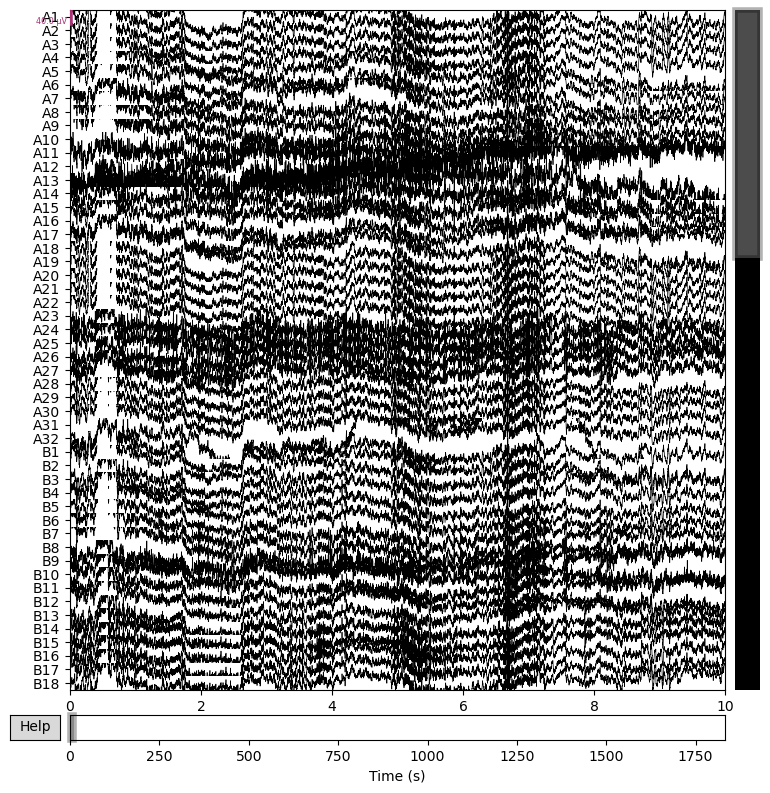

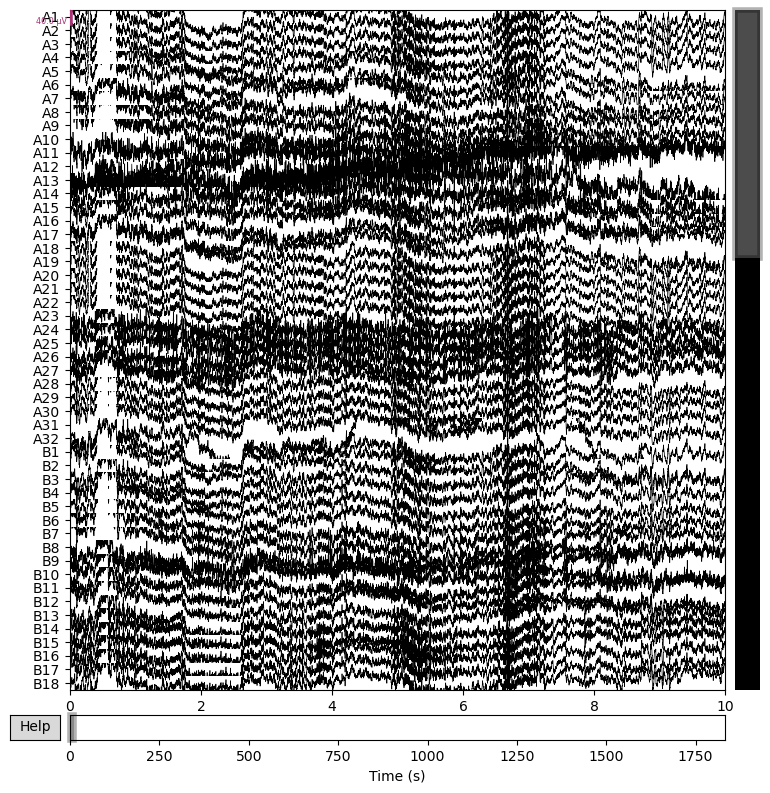

In [13]:
raw.plot(n_channels=50, title='EEG Raw Data (first 50 channels)')

In [14]:
# Apply a bandpass filter between 0.5 Hz and 100 Hz
raw_bandpass = raw.filter(l_freq=0.5, h_freq=100)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 1e+02 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 100.00 Hz
- Upper transition bandwidth: 25.00 Hz (-6 dB cutoff frequency: 112.50 Hz)
- Filter length: 6759 samples (6.601 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.2s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.4s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.5s remaining:    0.0s
[Parallel(n_jobs=1)]: Done 136 out of 136 | elapsed:   24.4s finished


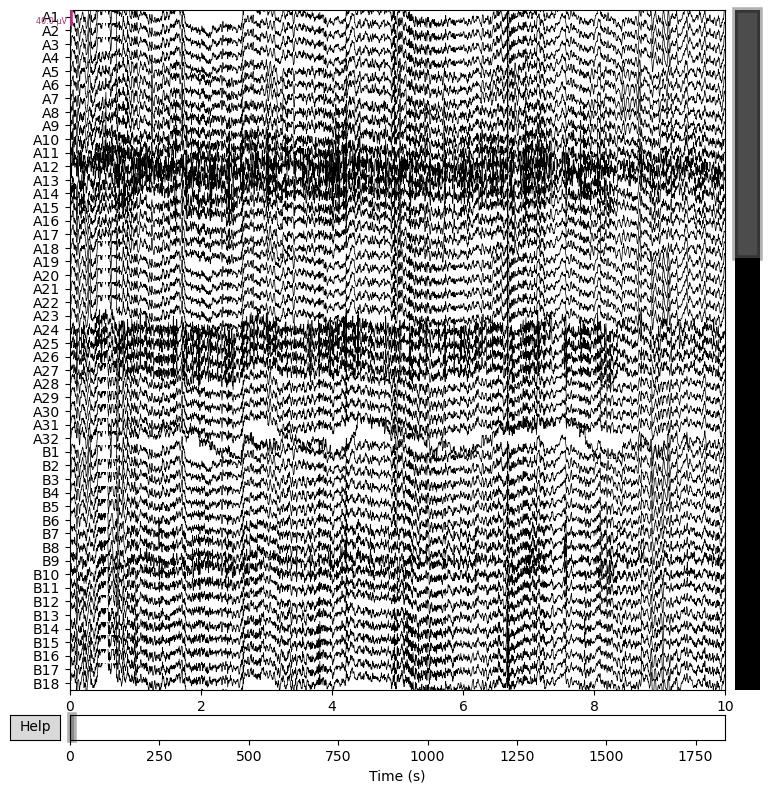

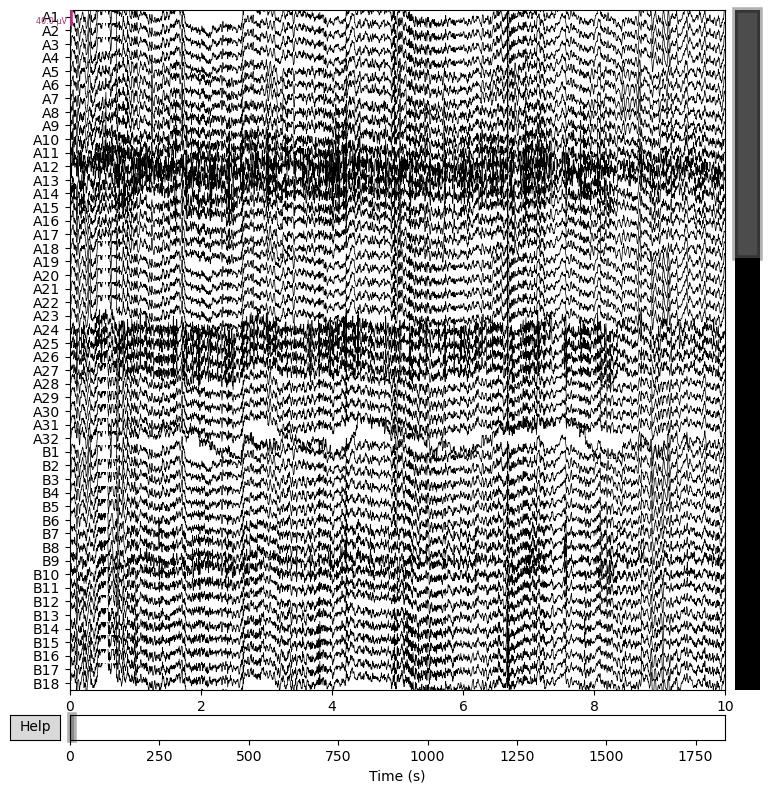

In [15]:
raw_bandpass.plot(n_channels=50, title='EEG Data (0.5-100 Hz Bandpass Filtered)', show=True)

NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
Effective window size : 2.000 (s)
Plotting power spectral density (dB=True).


C:\Users\windows\AppData\Local\Temp\ipykernel_16904\772319084.py:1: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw_bandpass.plot_psd(fmax= 125)
C:\Users\windows\anaconda3\Lib\site-packages\mne\viz\utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


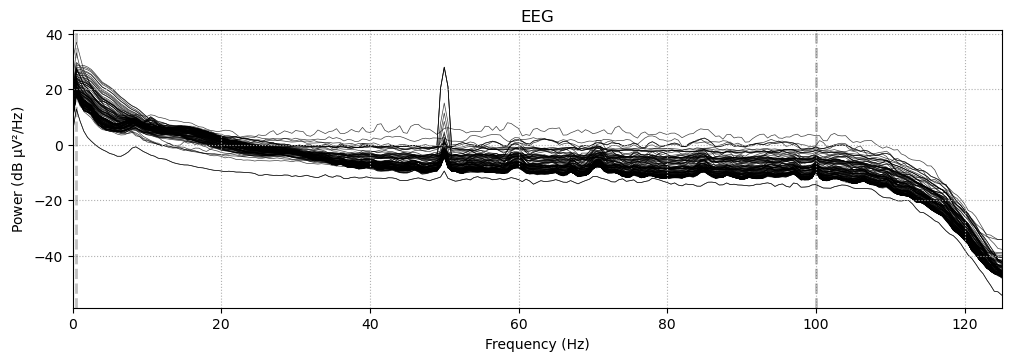

In [16]:
raw_bandpass.plot_psd(fmax= 125)

In [17]:
# Apply a notch filter at 50 Hz to remove line noise
raw_notch = raw_bandpass.notch_filter(freqs=50)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband edge: 50.62 Hz
- Upper transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 50.88 Hz)
- Filter length: 6759 samples (6.601 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.2s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.4s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.5s remaining:    0.0s
[Parallel(n_jobs=1)]: Done 136 out of 136 | elapsed:   24.7s finished


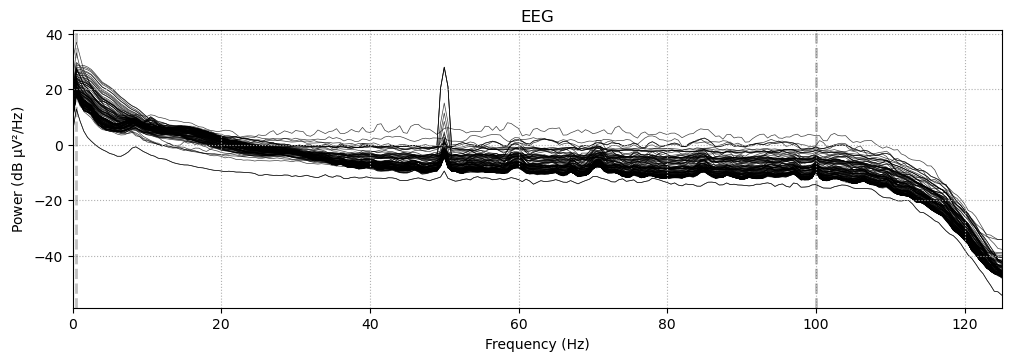

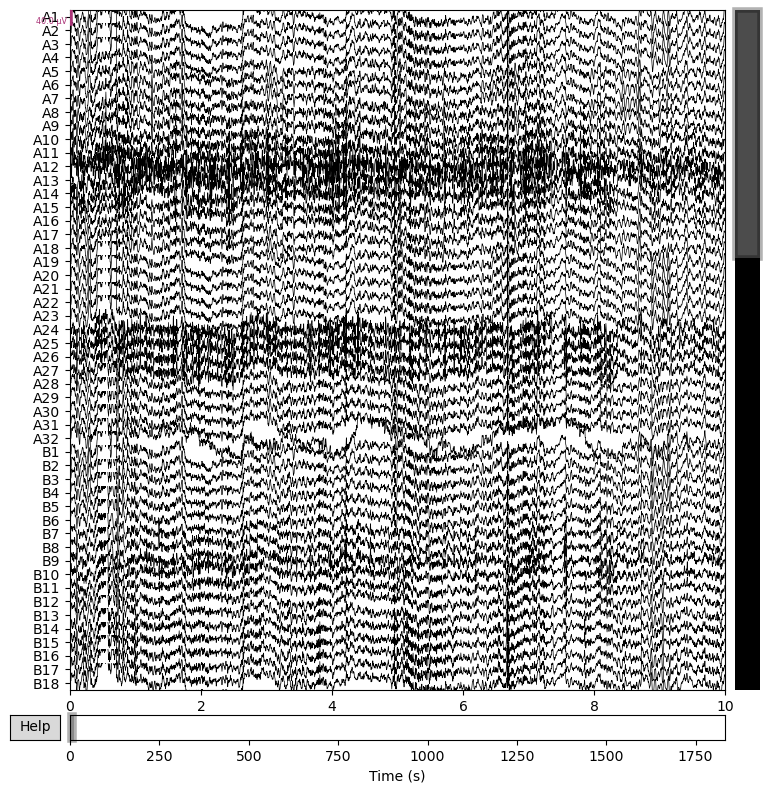

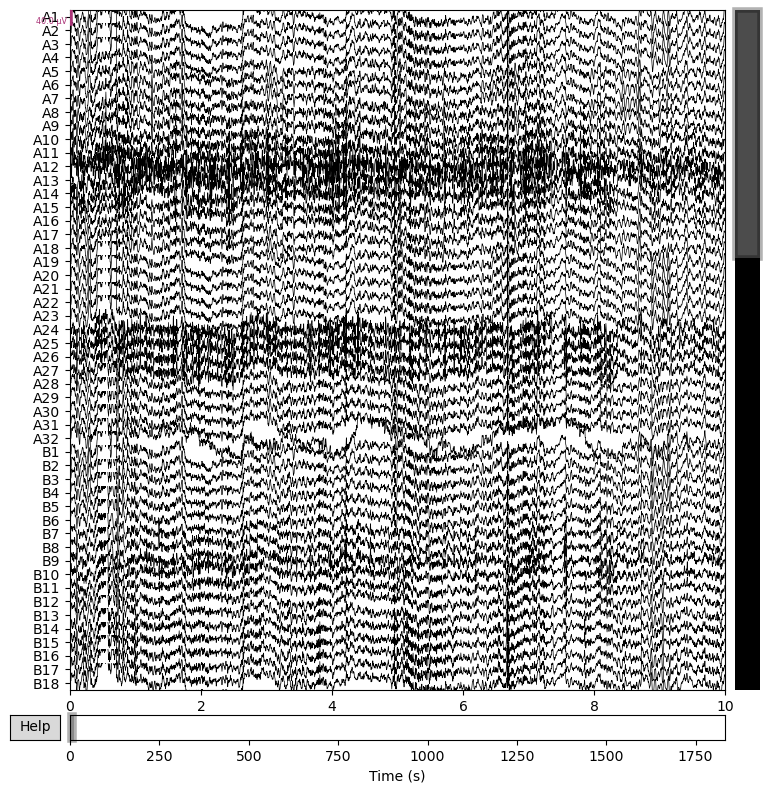

In [18]:
raw_notch.plot(n_channels=50, title='EEG Data (50 Hz Notch Filtered)', show=True)

NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
Effective window size : 2.000 (s)
Plotting power spectral density (dB=True).


C:\Users\windows\AppData\Local\Temp\ipykernel_16904\1338661116.py:1: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw_notch.plot_psd(fmax= 125)
C:\Users\windows\anaconda3\Lib\site-packages\mne\viz\utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


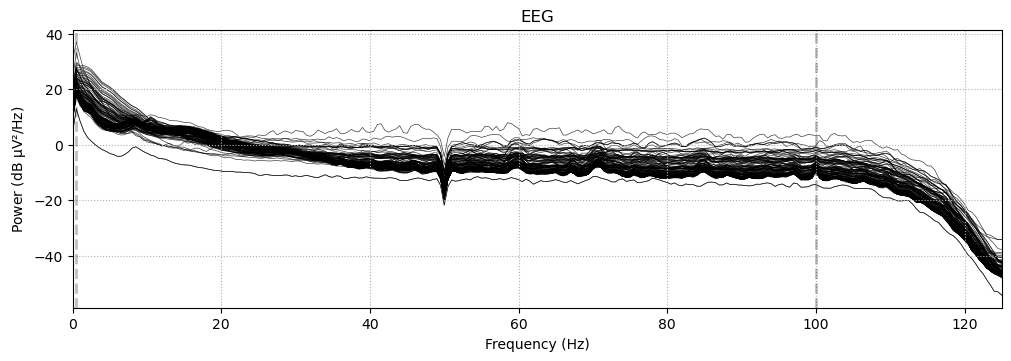

In [19]:
raw_notch.plot_psd(fmax= 125)

5. Epoching and decimation

In [20]:
# Print the sampling rate
print(f"Sampling rate: {raw_notch.info['sfreq']} Hz")

Sampling rate: 1024.0 Hz


In [21]:
# Resampling
raw_resample = raw_notch.resample(sfreq=254)
raw_resample

Trigger channel Status has a non-zero initial value of 65536 (consider using initial_event=True to detect this event)
Removing orphaned offset at the beginning of the file.
1112 events found on stim channel Status
Event IDs: [11 12 13 14 15 16 17 21 22 23 31 32 33 34 42 44 45 46 51 61 62 63 64]
Trigger channel Status has a non-zero initial value of 65536 (consider using initial_event=True to detect this event)
Removing orphaned offset at the beginning of the file.
1112 events found on stim channel Status
Event IDs: [11 12 13 14 15 16 17 21 22 23 31 32 33 34 42 44 45 46 51 61 62 63 64]


<RawEDF | sub-01_ses-01_task-innerspeech_eeg.bdf, 137 x 465328 (1832.0 s), ~486.5 MiB, data loaded>

In [22]:
# Check if events are correctly transformed after resampling
events_resampled = mne.find_events(raw_resample, shortest_event=1)

print("Original events shape:", events.shape)
print("Resampled events shape:", events_resampled.shape)

# Print the first 5 sample points of the original events
print("Original events sample points (first 5):", events[:5,0])

# Print the first 5 sample points of the resampled events
print("Resampled events sample points (first 5):", events_resampled[:5,0])

Trigger channel Status has a non-zero initial value of 65536 (consider using initial_event=True to detect this event)
Removing orphaned offset at the beginning of the file.
1112 events found on stim channel Status
Event IDs: [11 12 13 14 15 16 17 21 22 23 31 32 33 34 42 44 45 46 51 61 62 63 64]
Original events shape: (1112, 3)
Resampled events shape: (1112, 3)
Original events sample points (first 5): [ 6283 16591 31976 36150 36171]
Resampled events sample points (first 5): [1558 4115 7931 8967 8972]


In [23]:
# Print the resampled sampling rate
print(f"Sampling rate: {raw_resample.info['sfreq']} Hz")

Sampling rate: 254.0 Hz


In [27]:
# epoching
event_id = {'arriba': 31, 'abajo': 32, 'derecha': 33, 'izquierda': 34}

# Create a copy of the raw data and pick only EEG channels
exg_names = ['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8']
eeg_names = [ch for ch in raw_resample.ch_names if ch not in exg_names]

raw_eeg = raw_resample.copy().pick_channels(eeg_names)

# Create epochs from 0 to 4.5 seconds
epochs = mne.Epochs(raw_eeg, events, event_id=event_id, tmin=0, tmax=4.5,
                    baseline=None, preload=True, reject=None, flat=None)

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Not setting metadata
200 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 200 events and 1144 original time points ...
146 bad epochs dropped


In [28]:
# Load the BioSemi 128-channel montage
montage = mne.channels.make_standard_montage('biosemi128')

# Apply the montage to the epochs data
epochs.set_montage(montage)

<Epochs | 54 events (all good), 0 – 4.5 s (baseline off), ~60.9 MiB, data loaded,
 'arriba': 12
 'abajo': 14
 'derecha': 11
 'izquierda': 17>

In [31]:
print(epochs.get_montage())

<DigMontage | 0 extras (headshape), 0 HPIs, 3 fiducials, 128 channels>


In [32]:
print(epochs.info['dig'])

[<DigPoint |        LPA : (-86.1, -0.0, 0.0) mm     : head frame>, <DigPoint |     Nasion : (0.0, 86.1, 0.0) mm       : head frame>, <DigPoint |        RPA : (86.1, 0.0, 0.0) mm       : head frame>, <DigPoint |     EEG #1 : (0.0, 0.0, 135.1) mm      : head frame>, <DigPoint |     EEG #2 : (0.0, -18.1, 133.4) mm    : head frame>, <DigPoint |     EEG #3 : (0.0, -37.1, 127.6) mm    : head frame>, <DigPoint |     EEG #4 : (0.0, -53.1, 118.9) mm    : head frame>, <DigPoint |     EEG #5 : (-26.7, -62.9, 106.1) mm  : head frame>, <DigPoint |     EEG #6 : (-48.3, -48.3, 106.1) mm  : head frame>, <DigPoint |     EEG #7 : (-56.3, -56.3, 91.9) mm   : head frame>, <DigPoint |     EEG #8 : (-52.1, -71.8, 74.2) mm   : head frame>, <DigPoint |     EEG #9 : (-55.0, -75.7, 56.6) mm   : head frame>, <DigPoint |    EEG #10 : (-55.8, -76.8, 36.8) mm   : head frame>, <DigPoint |    EEG #11 : (-54.4, -74.9, 18.8) mm   : head frame>, <DigPoint |    EEG #12 : (-50.6, -69.7, 0.0) mm    : head frame>, <DigPoint

Independent components analysis

In [35]:
ica = ICA(n_components=128, random_state=97, method='infomax', fit_params=dict(extended=True))
ica.fit(epochs)

Fitting ICA to data using 128 channels (please be patient, this may take a while)
Selecting by number: 128 components
Computing Extended Infomax ICA
Fitting ICA took 483.1s.


Method,infomax
Fit parameters,extended=Truemax_iter=500
Fit,111 iterations on epochs (61776 samples)
ICA components,128
Available PCA components,128
Channel types,eeg
ICA components marked for exclusion,—


C:\Users\windows\AppData\Local\Temp\ipykernel_16904\1582586500.py:1: RuntimeWarning: The provided Epochs instance is not filtered between 1 and 100 Hz. ICLabel was designed to classify features extracted from an EEG dataset bandpass filtered between 1 and 100 Hz (see the 'filter()' method for Raw and Epochs instances).
  ic_labels = label_components(epochs, ica, method='iclabel')


Applying ICA to Epochs instance
    Transforming to ICA space (128 components)
    Zeroing out 18 ICA components
    Projecting back using 128 PCA components
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


C:\Users\windows\anaconda3\Lib\site-packages\mne\viz\utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


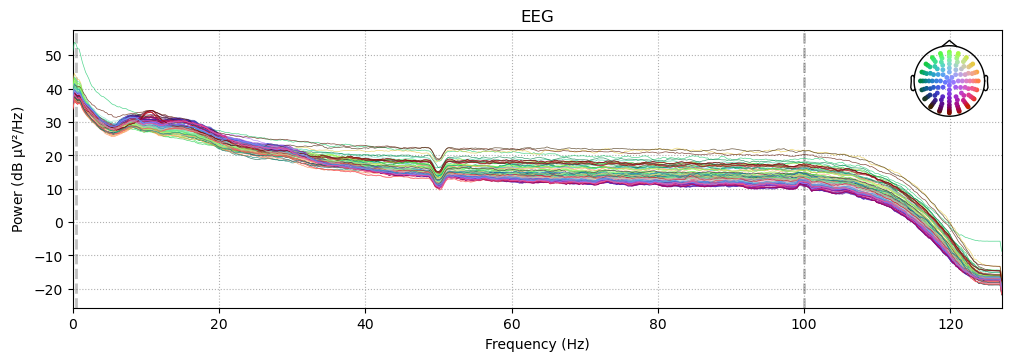

In [36]:
ic_labels = label_components(epochs, ica, method='iclabel')
labels = ic_labels["labels"]

exclude_idx = [idx for idx, label in enumerate(labels) if label not in ['brain', 'other']]
ica.exclude = exclude_idx

clean_epochs = ica.apply(epochs.copy())
clean_epochs.compute_psd().plot()

In [37]:
# Check the number of epochs
print(f"Total number of epochs: {len(clean_epochs)}")

Total number of epochs: 54


In [38]:
save_path = f"{base_path}/{subject}/{session}/eeg/{subject}_{session}_task-innerspeech_eeg-epo.fif"

# Save the cleaned epochs to the dynamically generated file path, overwriting if necessary
clean_epochs.save(save_path, overwrite=True)

[WindowsPath('D:/Users/windows/Desktop/EEG Inner Speech Decoding/Dataset/sub-01/ses-01/eeg/sub-01_ses-01_task-innerspeech_eeg-epo.fif')]